# **Lab 7(B) - Mathematical and Statistical Filters**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)
np.random.seed(0)   # reproducible noise

def show_pair(noisy, result, t1, t2):
    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(noisy, cmap='gray', vmin=0, vmax=255), plt.title(t1), plt.axis('off')
    plt.subplot(122), plt.imshow(result, cmap='gray', vmin=0, vmax=255), plt.title(t2), plt.axis('off')
    plt.tight_layout()
    plt.show()

## Adding noise to an Image

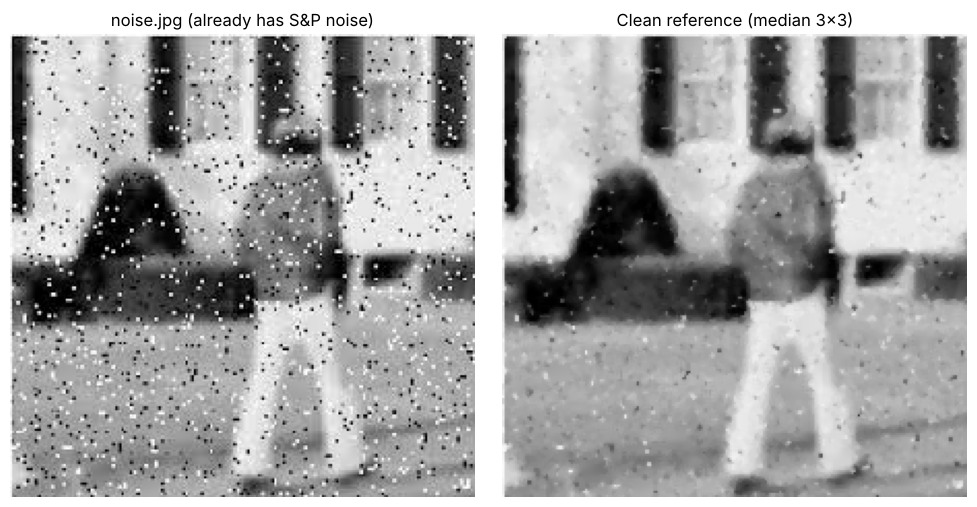

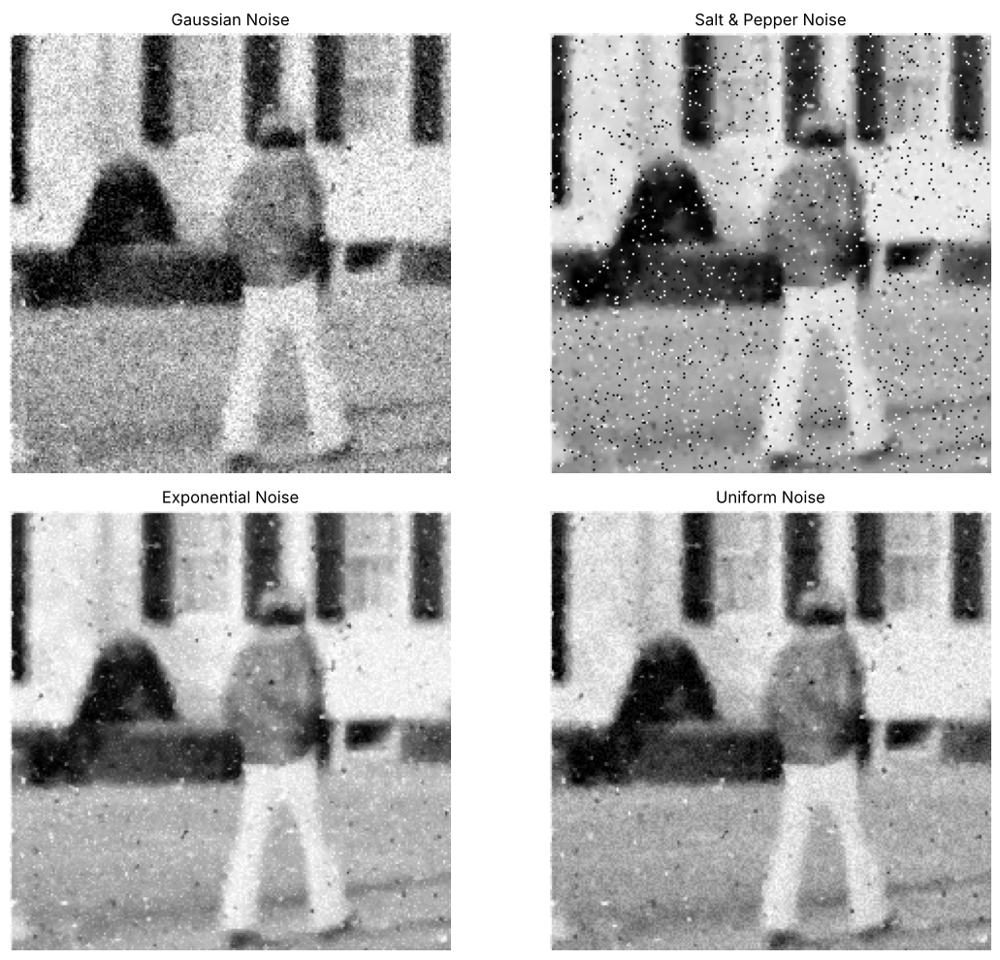

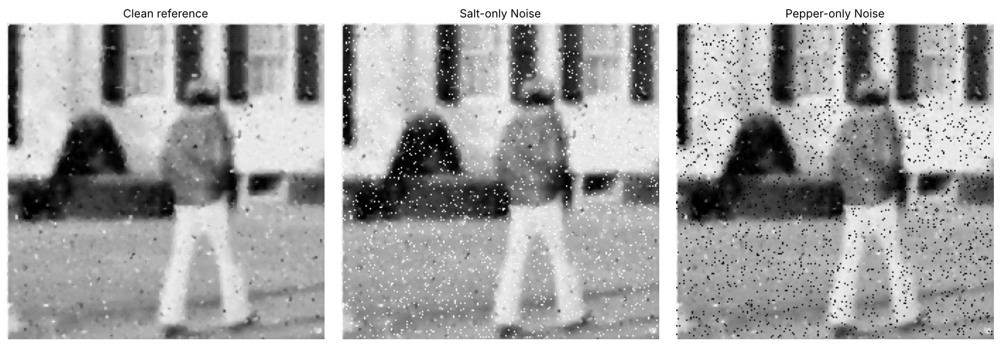

In [2]:
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = 'noise.jpg'

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform, Salt&Pepper, Salt-only, Pepper-only)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type in ("salt_pepper", "salt", "pepper"):
        s_vs_p = {"salt_pepper": 0.5, "salt": 1.0, "pepper": 0.0}[noise_type]
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)


# 2. Load image in grayscale
# noise.jpg ALREADY contains salt & pepper noise, so we first clean it with a 3x3 median
# and use that as our "clean" reference image. All experiments add noise to this clean image.
raw = cv2.imread(imgPath, 0)
img = cv2.medianBlur(raw, 3)
show_pair(raw, img, 'noise.jpg (already has S&P noise)', 'Clean reference (median 3x3)')

# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")
noise_salt = add_noise(img, "salt")      # used for contra-harmonic / min filter
noise_pepper = add_noise(img, "pepper")  # used for contra-harmonic / max filter

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Clean reference')
plt.subplot(132), plt.imshow(noise_salt, cmap='gray'), plt.title('Salt-only Noise')
plt.subplot(133), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper-only Noise')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Arithmetic Mean Filter**

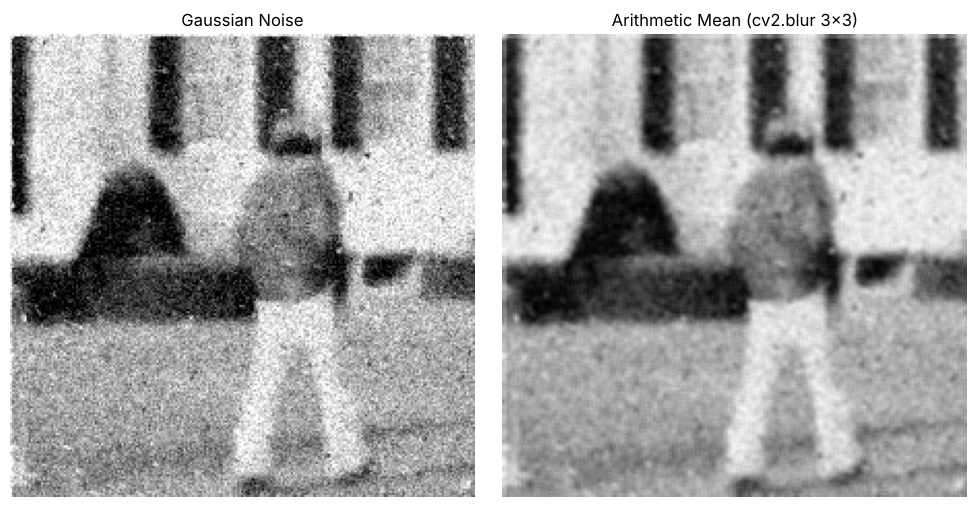

In [3]:
# --- METHOD 1: Using Built-in OpenCV function ---

# Apply Arithmetic Mean Filter (3x3 window)
# You can change kernel size to (5,5), (7,7) etc. — larger = smoother
filtered_img = cv2.blur(noise_gauss, (3, 3))

show_pair(noise_gauss, filtered_img, 'Gaussian Noise', 'Arithmetic Mean (cv2.blur 3x3)')

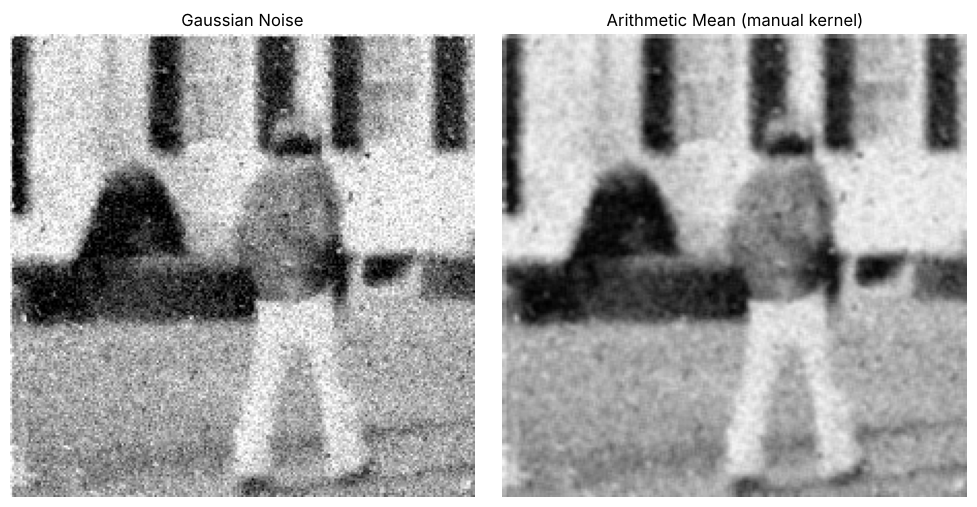

Max difference between Method 1 and Method 2: 0


In [4]:
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

show_pair(noise_gauss, arithmetic_mean_manual, 'Gaussian Noise', 'Arithmetic Mean (manual kernel)')

# Both methods should give (almost) the same result
print('Max difference between Method 1 and Method 2:',
      int(np.abs(filtered_img.astype(int) - arithmetic_mean_manual.astype(int)).max()))

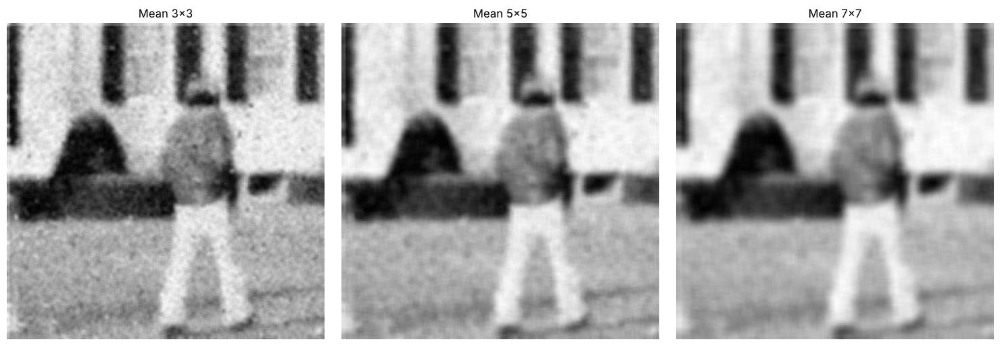

In [5]:
# Effect of kernel size
plt.figure(figsize=(15, 5))
for i, k in enumerate([3, 5, 7]):
    plt.subplot(1, 3, i + 1), plt.imshow(cv2.blur(noise_gauss, (k, k)), cmap='gray'), plt.title(f'Mean {k}x{k}'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Geometric Means**

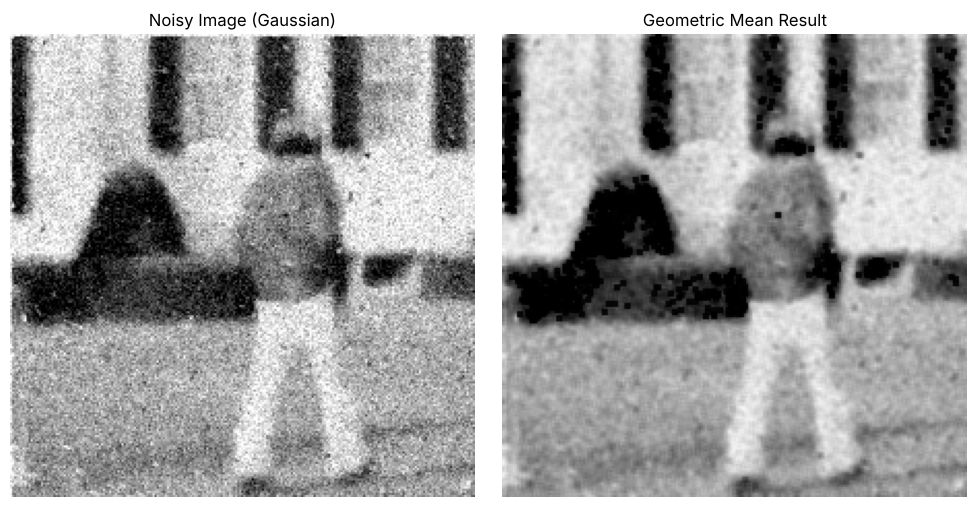

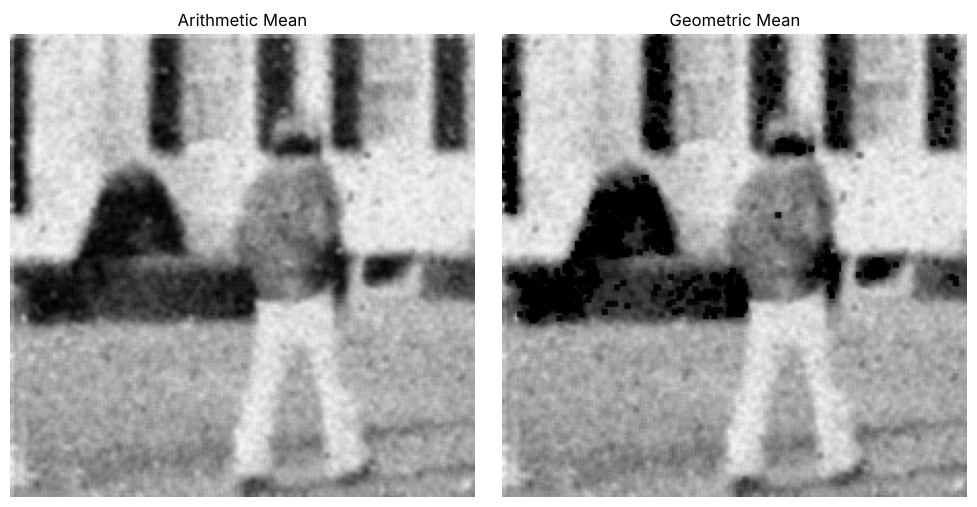

In [6]:
def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni, noise_pepper, noise_salt

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
show_pair(noise_img, result, 'Noisy Image (Gaussian)', 'Geometric Mean Result')

# Compare with the arithmetic mean
show_pair(filtered_img, result, 'Arithmetic Mean', 'Geometric Mean')

## **Harmonic Means Filter**

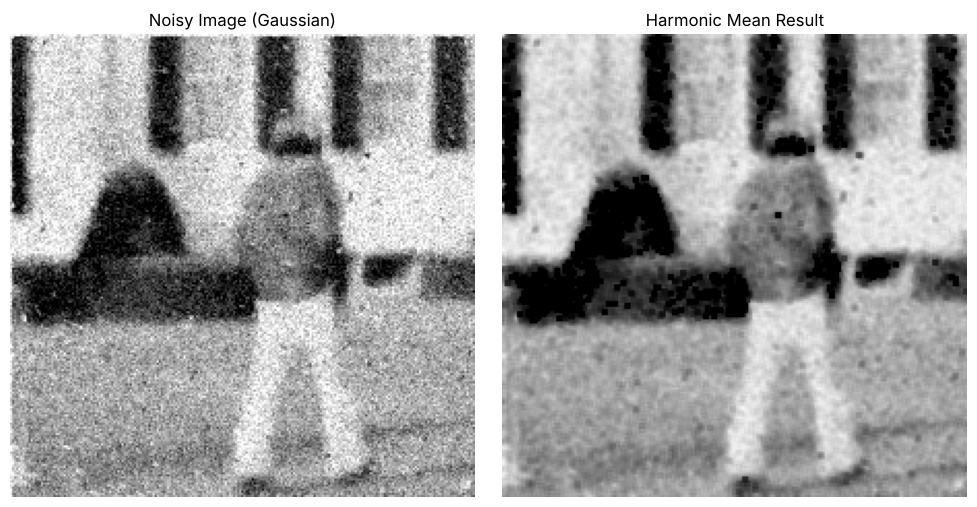

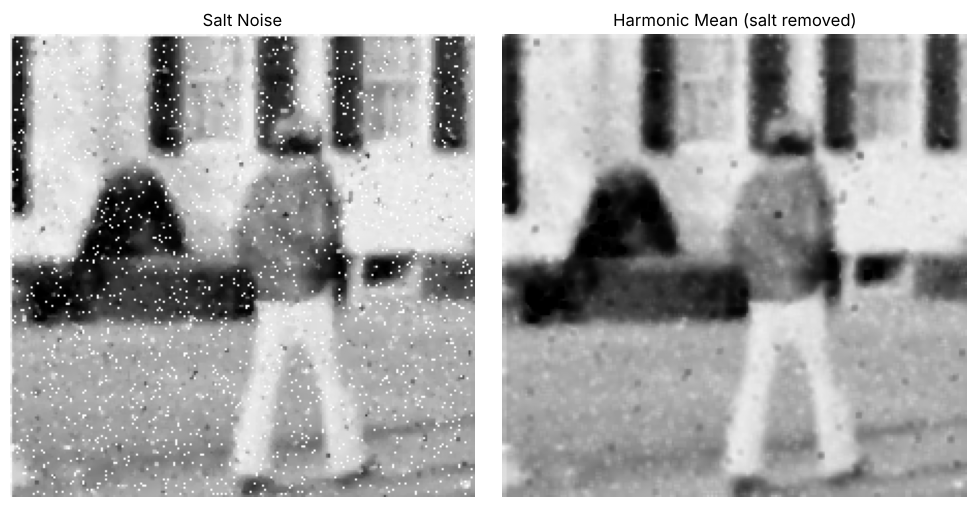

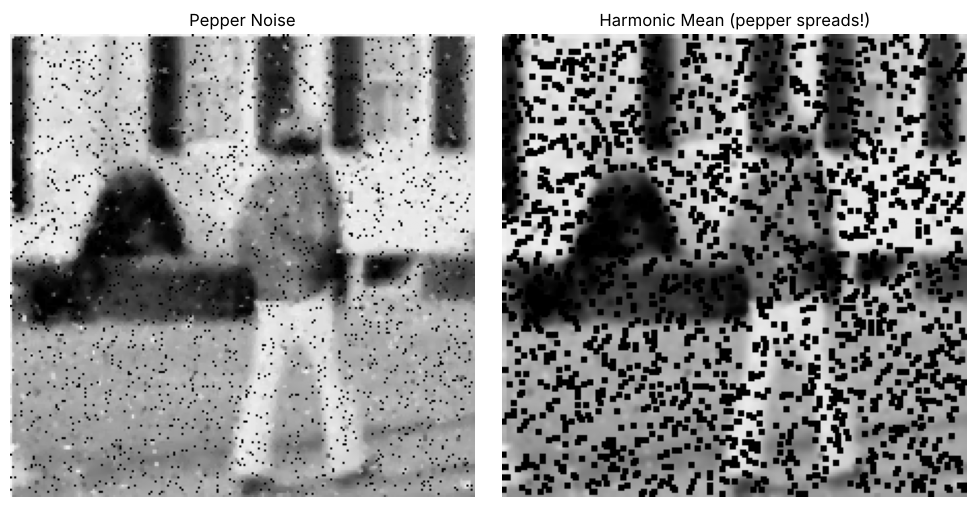

In [7]:
def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss, noise_sp, noise_expo, noise_uni, noise_pepper, noise_salt

noise_img = noise_gauss
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)
show_pair(noise_img, cleaned_img, 'Noisy Image (Gaussian)', 'Harmonic Mean Result')

# Harmonic mean works well for SALT noise but fails for PEPPER noise
show_pair(noise_salt, harmonic_mean_filter(noise_salt), 'Salt Noise', 'Harmonic Mean (salt removed)')
show_pair(noise_pepper, harmonic_mean_filter(noise_pepper), 'Pepper Noise', 'Harmonic Mean (pepper spreads!)')

## **Contra - Harmonic Mean Filter**

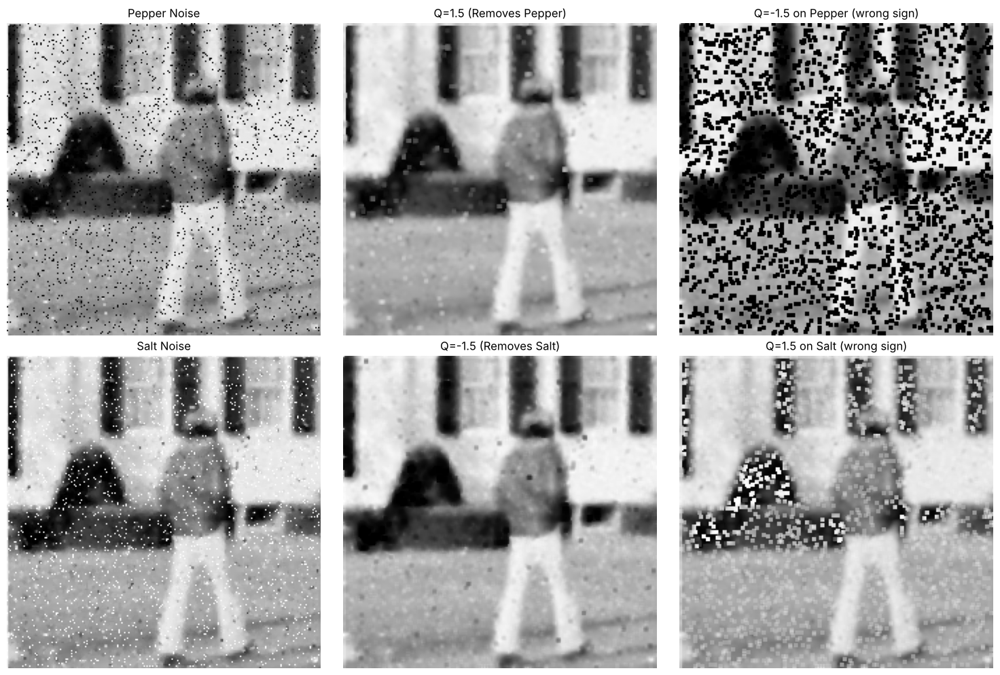

Q=0  vs arithmetic mean, max diff: 1
Q=-1 vs harmonic mean,  max diff: 1


In [8]:
def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)


# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_pepper, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_salt, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 10))
plt.subplot(231), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper Noise')
plt.subplot(232), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(233), plt.imshow(contra_harmonic_mean(noise_pepper, 3, Q=-1.5), cmap='gray'), plt.title('Q=-1.5 on Pepper (wrong sign)')
plt.subplot(234), plt.imshow(noise_salt, cmap='gray'), plt.title('Salt Noise')
plt.subplot(235), plt.imshow(salt_removed, cmap='gray'), plt.title('Q=-1.5 (Removes Salt)')
plt.subplot(236), plt.imshow(contra_harmonic_mean(noise_salt, 3, Q=1.5), cmap='gray'), plt.title('Q=1.5 on Salt (wrong sign)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

# Special cases: Q = 0 -> arithmetic mean, Q = -1 -> harmonic mean
print('Q=0  vs arithmetic mean, max diff:', int(np.abs(contra_harmonic_mean(noise_gauss, 3, 0).astype(int) - cv2.blur(noise_gauss, (3, 3)).astype(int)).max()))
print('Q=-1 vs harmonic mean,  max diff:', int(np.abs(contra_harmonic_mean(noise_gauss, 3, -1).astype(int) - harmonic_mean_filter(noise_gauss).astype(int)).max()))

## **Median Filter**

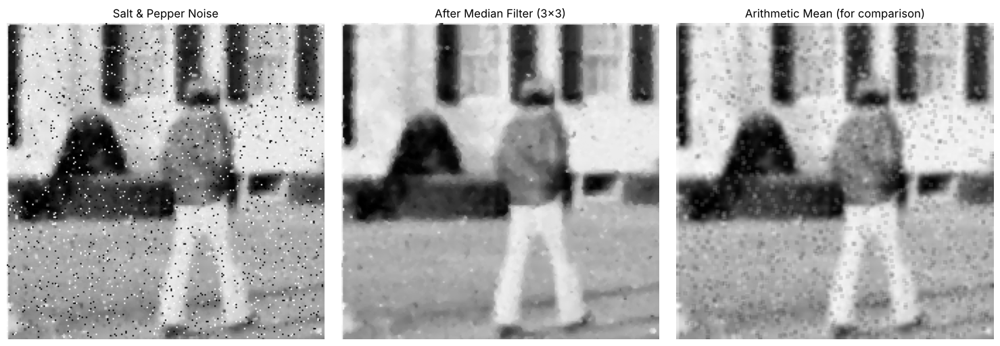

In [9]:
# Median is the best filter for Salt & Pepper noise
noise_img = noise_sp

# Apply Median Filter — ksize MUST be an odd integer (3, 5, 7, ...)
median_result = cv2.medianBlur(noise_img, 3)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Salt & Pepper Noise'), plt.axis('off')
plt.subplot(132), plt.imshow(median_result, cmap='gray'), plt.title('After Median Filter (3x3)'), plt.axis('off')
plt.subplot(133), plt.imshow(cv2.blur(noise_img, (3, 3)), cmap='gray'), plt.title('Arithmetic Mean (for comparison)'), plt.axis('off')
plt.tight_layout()
plt.show()

## **Max and Min Filter**

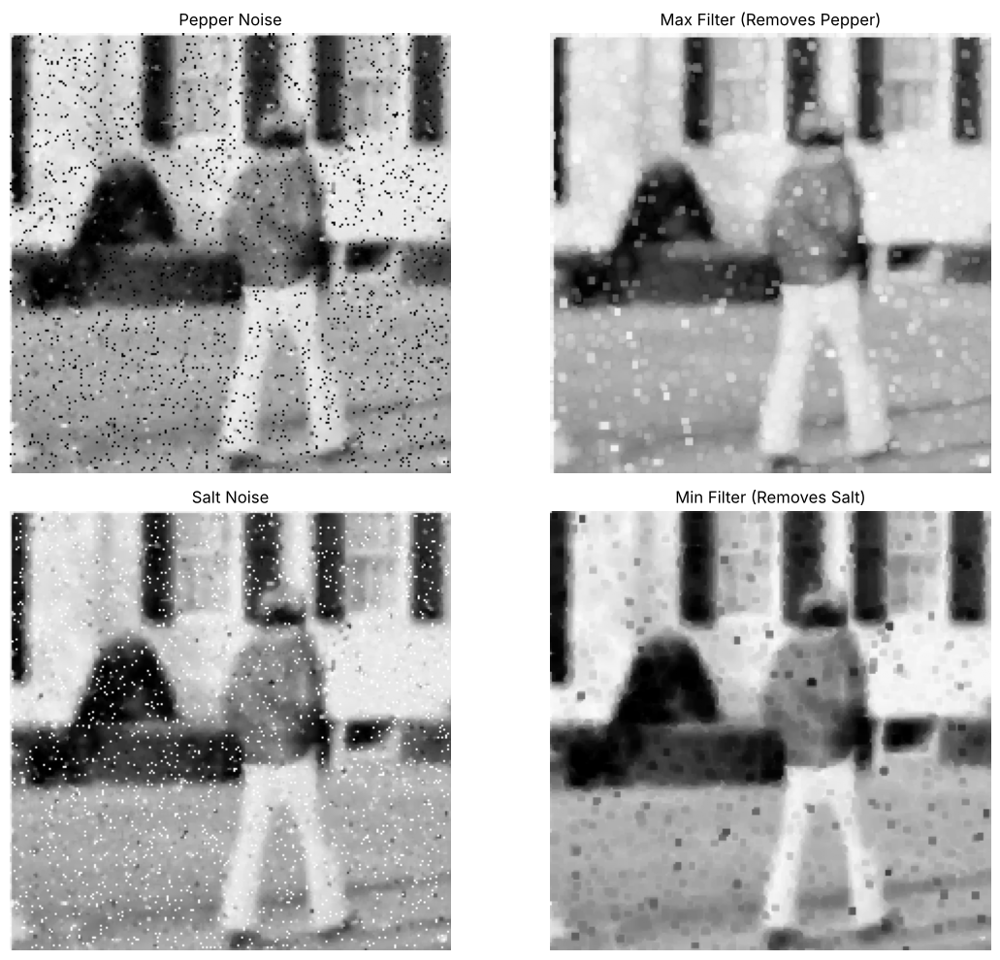

In [10]:
# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation) on PEPPER noise
# This picks the brightest pixel in the neighborhood -> black dots disappear.
max_filter = cv2.dilate(noise_pepper, kernel)

# 4. Apply Min Filter (Erosion) on SALT noise
# This picks the darkest pixel in the neighborhood -> white dots disappear.
min_filter = cv2.erode(noise_salt, kernel)

# --- Display Results ---
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_pepper, cmap='gray'), plt.title('Pepper Noise')
plt.subplot(222), plt.imshow(max_filter, cmap='gray'), plt.title('Max Filter (Removes Pepper)')
plt.subplot(223), plt.imshow(noise_salt, cmap='gray'), plt.title('Salt Noise')
plt.subplot(224), plt.imshow(min_filter, cmap='gray'), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Mid-Point Filtering**

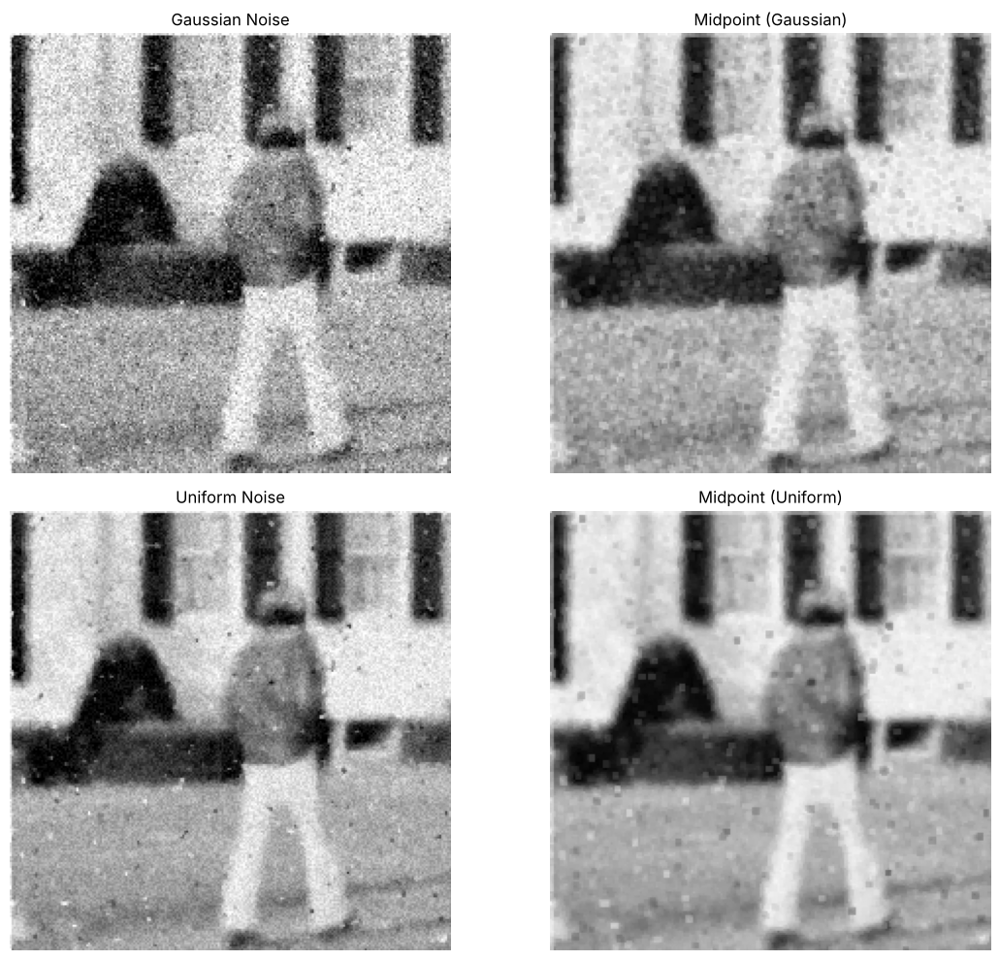

In [11]:
def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)


# Midpoint works best for randomly distributed noise like Gaussian / Uniform
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(midpoint_filter(noise_gauss), cmap='gray'), plt.title('Midpoint (Gaussian)')
plt.subplot(223), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')
plt.subplot(224), plt.imshow(midpoint_filter(noise_uni), cmap='gray'), plt.title('Midpoint (Uniform)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## **Comparison of all filters on all noise types (PSNR)**
PSNR (dB) is measured against the clean reference image — higher is better. The best filter for each noise type is reported below the table.

In [12]:
def psnr(ref, test):
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

filters = {
    'Arithmetic': lambda x: cv2.blur(x, (3, 3)),
    'Geometric':  geometric_mean_filter,
    'Harmonic':   harmonic_mean_filter,
    'Contra Q=1.5':  lambda x: contra_harmonic_mean(x, 3, 1.5),
    'Contra Q=-1.5': lambda x: contra_harmonic_mean(x, 3, -1.5),
    'Median':     lambda x: cv2.medianBlur(x, 3),
    'Max':        lambda x: cv2.dilate(x, np.ones((3, 3), np.uint8)),
    'Min':        lambda x: cv2.erode(x, np.ones((3, 3), np.uint8)),
    'Midpoint':   midpoint_filter,
}
noises = {'Gaussian': noise_gauss, 'Salt&Pepper': noise_sp, 'Salt': noise_salt,
          'Pepper': noise_pepper, 'Exponential': noise_expo, 'Uniform': noise_uni}

print(f"{'Filter':<15}" + ''.join(f'{n:>13}' for n in noises))
print(f"{'(no filter)':<15}" + ''.join(f'{psnr(img, x):13.2f}' for x in noises.values()))
for fname, f in filters.items():
    print(f'{fname:<15}' + ''.join(f'{psnr(img, f(x)):13.2f}' for x in noises.values()))

print()
for n, x in noises.items():
    best = max(filters, key=lambda k: psnr(img, filters[k](x)))
    print(f'Best filter for {n:<12}: {best}')

Filter              Gaussian  Salt&Pepper         Salt       Pepper  Exponential      Uniform
(no filter)            20.38        19.04        20.57        17.62        25.57        26.92
Arithmetic             25.65        24.99        25.32        23.65        25.16        27.31
Geometric              23.17        12.50        26.30         9.67        25.38        25.88
Harmonic               22.00        11.53        25.90         8.77        25.19        24.96
Contra Q=1.5           22.86        18.34        15.76        25.78        23.03        25.12
Contra Q=-1.5          21.15        11.51        25.41         8.76        24.99        24.27
Median                 26.13        31.79        31.63        30.59        27.44        29.42
Max                    15.34        13.76        11.33        21.19        16.55        18.98
Min                    14.82        11.26        21.06         8.65        22.12        18.77
Midpoint               24.17        16.38        17.90      

## Observations
1. **Arithmetic mean** reduces Gaussian / uniform noise but blurs edges, and the blur grows with kernel size (3→5→7). Method 1 (`cv2.blur`) and Method 2 (manual kernel with `filter2D`) give identical results (max difference = 0).
2. **Geometric mean** smooths about as much as the arithmetic mean but keeps a bit more detail. Because it multiplies pixel values, a single 0 (pepper) pulls the whole window toward black, so it fails badly on pepper noise.
3. **Harmonic mean** works well on **salt** noise (PSNR ≈ 25.9 dB) but fails on **pepper** noise (≈ 8.8 dB): black dots spread into dark blobs.
4. **Contra-harmonic mean**: **Q > 0 removes pepper** (25.8 dB on pepper) and **Q < 0 removes salt** (25.4 dB on salt). Using the wrong sign makes things much worse. Q = 0 gives the arithmetic mean and Q = −1 gives the harmonic mean (max difference ≤ 1 from rounding).
5. The **median filter** is the best for salt & pepper noise (≈ 31.8 dB versus 25.0 dB for the arithmetic mean) and keeps edges sharp. It came out on top for every noise type here. Note: the clean reference was itself made with a 3×3 median, which gives the median filter a small advantage in this table.
6. The **max filter** (dilation) removes pepper and the **min filter** (erosion) removes salt. Each one makes the opposite noise worse, and both shift overall brightness (max makes the image brighter, min makes it darker).
7. The **midpoint filter** suits random, evenly spread noise such as **uniform** (26.5 dB) and Gaussian. It does poorly on impulse noise, because the extreme values (0 and 255) are exactly what it averages.

**Conclusion:** use the median filter (or contra-harmonic / max / min when you know the noise is only salt or only pepper) for impulse noise. Use the arithmetic, geometric or midpoint filter for Gaussian or uniform noise.